\Tic-Tac-Toe Optimal Move Predictor

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# Load CSVs
#uploaded = files.upload()
#train = pd.read_csv('train.csv')
#val = pd.read_csv('val.csv')
train = pd.read_csv('/content/sample_data/train.csv')
val = pd.read_csv('/content/sample_data/val.csv')

# Quick look table
print("Training set shape:", train.shape)
print("Validation set shape:", val.shape)
print("\nFirst 10 rows of training data:")
train.head(10)

Training set shape: (3164, 11)
Validation set shape: (678, 11)

First 10 rows of training data:


,p1,p2,p3,p4,p5,p6,p7,p8,p9,turn,label_move_cell
0,1,-1,0,1,1,0,-1,0,-1,1,5
1,0,-1,0,-1,-1,1,-1,1,1,-1,2
2,1,0,0,-1,0,-1,-1,0,1,-1,4
3,-1,0,1,-1,1,0,0,0,-1,-1,6
4,1,-1,1,1,-1,-1,0,0,-1,-1,6
5,0,1,-1,-1,-1,0,1,-1,1,-1,5
6,0,-1,1,0,0,0,-1,-1,1,-1,4
7,-1,1,-1,0,0,1,-1,0,0,-1,3
8,0,1,0,1,-1,-1,-1,1,0,1,2
9,-1,0,-1,0,-1,1,1,0,0,-1,1


**Checking the label distribution in the training set:**

Label counts in training set:
label_move_cell
0    765
1    395
2    468
3    253
4    489
5    173
6    273
7    117
8    231
Name: count, dtype: int64


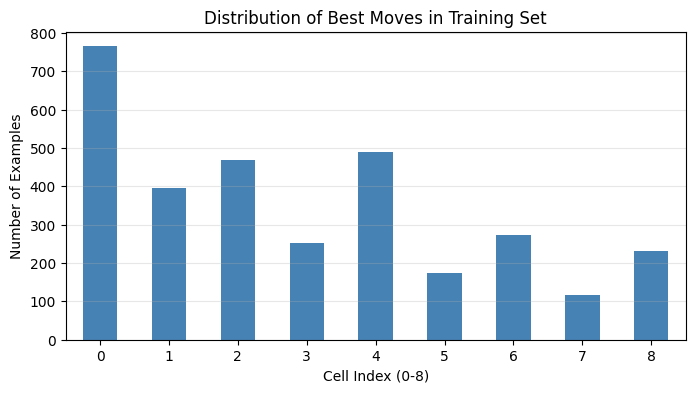

In [ ]:
# Cell 2: Check label distribution
print("Label counts in training set:")
print(train['label_move_cell'].value_counts().sort_index())

# Visualize it
plt.figure(figsize=(8, 4))
train['label_move_cell'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Distribution of Best Moves in Training Set')
plt.xlabel('Cell Index (0-8)')
plt.ylabel('Number of Examples')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.show()

**Vistlize 3 random boards from the Dataset :**

In [ ]:

def draw_board(row):

    # Get the 9 cells
    cells = row[['p1','p2','p3','p4','p5','p6','p7','p8','p9']].values
    turn = row['turn']
    label = row['label_move_cell']

    # Convert numbers to symbols based on whose turn it is
    # Current player (1) = X, Opponent (-1) = O
    symbols = []
    for v in cells:
        if v == 1:
            symbols.append('X' if turn == 1 else 'O')
        elif v == -1:
            symbols.append('O' if turn == 1 else 'X')
        else:
            symbols.append('.')

    # Print as 3x3 grid
    print(f"Turn: {'X' if turn == 1 else 'O'} to play")
    print(f"Best move (label): cell {label}")
    print()
    print(f" {symbols[0]} | {symbols[1]} | {symbols[2]} ")
    print("-----------")
    print(f" {symbols[3]} | {symbols[4]} | {symbols[5]} ")
    print("-----------")
    print(f" {symbols[6]} | {symbols[7]} | {symbols[8]} ")
    print()

# Pick 3 random rows and draw them
sample = train.sample(3, random_state=42)
for idx, row in sample.iterrows():
    print(f"--- Row {idx} ---")
    draw_board(row)

--- Row 2618 ---
Turn: O to play
Best move (label): cell 4

 O | . | X 
-----------
 O | . | X 
-----------
 X | X | O 

--- Row 346 ---
Turn: O to play
Best move (label): cell 4

 . | X | . 
-----------
 O | . | . 
-----------
 . | X | . 

--- Row 170 ---
Turn: O to play
Best move (label): cell 1

 X | . | X 
-----------
 O | . | . 
-----------
 . | . | . 



**Split features and labels for train and validation**

In [ ]:
feature_cols = ['p1','p2','p3','p4','p5','p6','p7','p8','p9','turn']
target_col = 'label_move_cell'

X_train = train[feature_cols]
y_train = train[target_col]

X_val = val[feature_cols]
y_val = val[target_col]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_val shape:  ", X_val.shape)
print("y_val shape:  ", y_val.shape)

print("\nFirst row of X_train:")
print(X_train.iloc[0].values)
print("Corresponding y_train:", y_train.iloc[0])

X_train shape: (3164, 10)
y_train shape: (3164,)
X_val shape:   (678, 10)
y_val shape:   (678,)

First row of X_train:
[ 1 -1  0  1  1  0 -1  0 -1  1]
Corresponding y_train: 5


# MLP

**( WITHOUT ) Feature Engineering**

In [ ]:
# Import libraries
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, log_loss
import time

# Build baseline MLP (no feature engineering)
MLPmodel = MLPClassifier(
    hidden_layer_sizes=( 64, 32),  # 2 hidden layers
    activation='relu',                  # activation function
    max_iter=500,                       # max epochs
    early_stopping=True,                # stop if no improvement
    alpha=0.05,                         # L2 regularization
    n_iter_no_change=10,                # patience
    random_state=42
)

# Train and measure time
start = time.time()
MLPmodel.fit(X_train, y_train)
train_time = time.time() - start

# Predictions
train_preds3 = MLPmodel.predict(X_train)
val_preds3   = MLPmodel.predict(X_val)

# Probabilities for log-loss
train_proba3 = MLPmodel.predict_proba(X_train)
val_proba3   = MLPmodel.predict_proba(X_val)

# Calculate metrics
train_acc  = accuracy_score(y_train, train_preds3)
val_acc    = accuracy_score(y_val,   val_preds3)
train_loss = log_loss(y_train, train_proba3)
val_loss   = log_loss(y_val,   val_proba3)

# Print results
print("Baseline MLP (no feature engineering)")
print(f"Train Accuracy : {train_acc:.4f}")
print(f"Val   Accuracy : {val_acc:.4f}")
print(f"Accuracy Gap   : {(train_acc - val_acc)*100:.2f} pp")
print()
print(f"Train Log-Loss : {train_loss:.4f}")
print(f"Val   Log-Loss : {val_loss:.4f}")
print(f"Loss Gap       : {val_loss - train_loss:.4f}")
print()
print(f"Training time  : {train_time:.2f}s")


Baseline MLP (no feature engineering)
Train Accuracy : 0.8641
Val   Accuracy : 0.7861
Accuracy Gap   : 7.80 pp

Train Log-Loss : 0.4114
Val   Log-Loss : 0.5913
Loss Gap       : 0.1800

Training time  : 1.14s


**Feature Engineering**

In [ ]:
def add_strategic_features(df):
    df = df.copy()

    # 8 possible winning lines (rows, columns, diagonals)
    lines = [
        [0,1,2], [3,4,5], [6,7,8],
        [0,3,6], [1,4,7], [2,5,8],
        [0,4,8], [2,4,6]
    ]

    # Convert board to numpy array for speed
    board = df[['p1','p2','p3','p4','p5','p6','p7','p8','p9']].values

    # Initialize feature lists
    my_two_in_row  = []
    opp_two_in_row = []
    my_fork        = []
    opp_fork       = []
    center_free    = []
    my_corners     = []
    empty_cells    = []

    # Four corner indices
    corners = [0, 2, 6, 8]

    for b in board:
        my_2, opp_2 = 0, 0

        # Check each winning line for threats
        for line in lines:
            vals = [b[i] for i in line]
            if vals.count(1)  == 2 and vals.count(0) == 1:
                my_2  += 1    # player threatens to win
            if vals.count(-1) == 2 and vals.count(0) == 1:
                opp_2 += 1    # opponent threatens to win

        my_two_in_row.append(my_2)
        opp_two_in_row.append(opp_2)
        my_fork.append(1 if my_2 >= 2 else 0)        # player has a fork
        opp_fork.append(1 if opp_2 >= 2 else 0)      # opponent has a fork
        center_free.append(1 if b[4] == 0 else 0)    # center cell is empty
        my_corners.append(sum(1 for c in corners if b[c] == 1))  # corners owned by player
        empty_cells.append(list(b).count(0))          # remaining empty cells

    # Add features to dataframe
    df['my_two_in_row']  = my_two_in_row
    df['opp_two_in_row'] = opp_two_in_row
    df['my_fork']        = my_fork
    df['opp_fork']       = opp_fork
    df['center_free']    = center_free
    df['my_corners']     = my_corners
    df['empty_cells']    = empty_cells

    return df

# Apply to train and validation sets
train_fe = add_strategic_features(train)
val_fe   = add_strategic_features(val)

Train with features Engineering

In [ ]:
# Define feature columns (original + engineered)
feature_cols_fe = ['p1','p2','p3','p4','p5','p6','p7','p8','p9','turn',
                   'my_two_in_row','opp_two_in_row',
                   'my_fork','opp_fork',
                   'center_free','my_corners','empty_cells']
# Split into X and y
X_train_fe = train_fe[feature_cols_fe]
y_train_fe = train_fe['label_move_cell']
X_val_fe   = val_fe[feature_cols_fe]
y_val_fe   = val_fe['label_move_cell']

# Feature count summary
print(f"Original features : {X_train.shape[1]}")
print(f"New features      : {X_train_fe.shape[1]}")
print(f"Added features    : {X_train_fe.shape[1] - X_train.shape[1]}")

# Build MLP with regularization to reduce overfitting
MLPmodel_fe = MLPClassifier(
    hidden_layer_sizes=(64, 32),  # smaller network to reduce overfitting
    activation='relu',
    max_iter=500,
    early_stopping=True,
   alpha=0.05,                   # L2 regularization
    n_iter_no_change=10,          # stop early if no improvement
    random_state=42
)

# Train the model
MLPmodel_fe.fit(X_train_fe, y_train_fe)

# Predictions
train_preds_fe = MLPmodel_fe.predict(X_train_fe)
val_preds_fe   = MLPmodel_fe.predict(X_val_fe)

train_proba_fe = MLPmodel_fe.predict_proba(X_train_fe)
val_proba_fe   = MLPmodel_fe.predict_proba(X_val_fe)

# Calculate accuracy and log-loss
train_acc_fe  = accuracy_score(y_train_fe, train_preds_fe)
val_acc_fe    = accuracy_score(y_val_fe,   val_preds_fe)
train_loss_fe = log_loss(y_train_fe, train_proba_fe)
val_loss_fe   = log_loss(y_val_fe,   val_proba_fe)

# Print results
print("MLP (with feature engineering)")
print(f"Train Accuracy : {train_acc_fe:.4f}")
print(f"Val   Accuracy : {val_acc_fe:.4f}")
print(f"Accuracy Gap   : {(train_acc_fe - val_acc_fe)*100:.2f}")
print()
print(f"Train Log-Loss : {train_loss_fe:.4f}")
print(f"Val   Log-Loss : {val_loss_fe:.4f}")
print(f"Loss Gap       : {val_loss_fe - train_loss_fe:.4f}")

Original features : 10
New features      : 17
Added features    : 7
MLP (with feature engineering)
Train Accuracy : 0.9314
Val   Accuracy : 0.8584
Accuracy Gap   : 7.30

Train Log-Loss : 0.2365
Val   Log-Loss : 0.4352
Loss Gap       : 0.1986


 Save the final model

In [ ]:
import joblib

# Save the final model
joblib.dump(MLPmodel_fe, 'MLP_final_model.pkl')
print("Model saved successfully!")

Model saved successfully!
